<a href="https://colab.research.google.com/github/yunioktasafitri/Tugas-Besar-Big-Data/blob/main/EDA_Kelompok9_Mahadata.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [48]:
path = "/content/drive/MyDrive/mahadata/"

df_owid = spark.read.csv(path + "owid-covid-data.csv", header=True, inferSchema=True)
df_vax  = spark.read.csv(path + "country_vaccinations.csv.xls", header=True, inferSchema=True)
df_who = spark.read.csv(path + "WHO-COVID-19-global-data.csv.xls",
                        header=True, inferSchema=True, sep=";")

df_who.show(3)

+-------------+------------+-----------+----------+---------+----------------+----------+-----------------+
|Date_reported|Country_code|    Country|WHO_region|New_cases|Cumulative_cases|New_deaths|Cumulative_deaths|
+-------------+------------+-----------+----------+---------+----------------+----------+-----------------+
|   05/01/2020|          AF|Afghanistan|      EMRO|     NULL|               0|      NULL|                0|
|   12/01/2020|          AF|Afghanistan|      EMRO|     NULL|               0|      NULL|                0|
|   19/01/2020|          AF|Afghanistan|      EMRO|     NULL|               0|      NULL|                0|
+-------------+------------+-----------+----------+---------+----------------+----------+-----------------+
only showing top 3 rows


In [47]:
df_who.printSchema()

root
 |-- Date_reported: date (nullable = true)
 |-- Country_code: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- WHO_region: string (nullable = true)
 |-- New_cases: integer (nullable = true)
 |-- Cumulative_cases: integer (nullable = true)
 |-- New_deaths: integer (nullable = true)
 |-- Cumulative_deaths: integer (nullable = true)



In [49]:
df_who = df_who.withColumn("Date_reported", F.to_date("Date_reported", "dd/MM/yyyy"))
df_who.select(F.min("Date_reported"), F.max("Date_reported")).show()

+------------------+------------------+
|min(Date_reported)|max(Date_reported)|
+------------------+------------------+
|        2020-01-05|        2024-08-11|
+------------------+------------------+



In [36]:
for nama, d, kol_nama, kol_tgl in [("OWID", df_owid, "location", "date"),
                                   ("VAX", df_vax, "country", "date"),
                                   ("WHO", df_who, "Country", "Date_reported")]:
    print(nama, "| baris:", d.count(), "| kolom:", len(d.columns),
          "| entitas:", d.select(kol_nama).distinct().count())
    d.select(F.min(kol_tgl), F.max(kol_tgl)).show()
df_owid.printSchema()

OWID | baris: 320272 | kolom: 68 | entitas: 255
+----------+----------+
| min(date)| max(date)|
+----------+----------+
|2020-01-01|2023-06-25|
+----------+----------+

VAX | baris: 86512 | kolom: 15 | entitas: 223
+----------+----------+
| min(date)| max(date)|
+----------+----------+
|2020-12-02|2022-03-29|
+----------+----------+

WHO | baris: 57840 | kolom: 8 | entitas: 240
+------------------+------------------+
|min(Date_reported)|max(Date_reported)|
+------------------+------------------+
|        2020-01-05|        2024-08-11|
+------------------+------------------+

root
 |-- index: integer (nullable = true)
 |-- iso_code: string (nullable = true)
 |-- continent: string (nullable = true)
 |-- location: string (nullable = true)
 |-- date: date (nullable = true)
 |-- total_cases: double (nullable = true)
 |-- new_cases: double (nullable = true)
 |-- new_cases_smoothed: double (nullable = true)
 |-- total_deaths: double (nullable = true)
 |-- new_deaths: double (nullable = true)


In [37]:
!ls -lh /content/drive/MyDrive/mahadata/

total 103M
-rw------- 1 root root  17M Oct 22 13:00 country_vaccinations.csv.xls
-rw------- 1 root root  84M Oct 22 12:58 owid-covid-data.csv
-rw------- 1 root root 2.7M Oct 22 12:57 WHO-COVID-19-global-data.csv.xls


In [38]:
def pct_null(df, cols):
    total = df.count()
    df.select([(F.sum(F.col(c).isNull().cast("int")) / total * 100).alias(c) for c in cols]).show(truncate=False)

pct_null(df_owid, ["new_cases", "new_deaths", "total_vaccinations", "people_vaccinated_per_hundred", "population"])
pct_null(df_vax, ["total_vaccinations", "people_vaccinated", "people_fully_vaccinated", "daily_vaccinations"])
pct_null(df_who, ["New_cases", "New_deaths"])

print("Duplikat OWID:", df_owid.count() - df_owid.dropDuplicates(["location", "date"]).count())
print("Duplikat VAX :", df_vax.count() - df_vax.dropDuplicates(["country", "date"]).count())
print("Duplikat WHO :", df_who.count() - df_who.dropDuplicates(["Country", "Date_reported"]).count())

print("Baris agregat OWID:", df_owid.filter(F.col("iso_code").startswith("OWID_")).count())
print("new_cases negatif:", df_owid.filter(F.col("new_cases") < 0).count())
print("new_deaths negatif:", df_owid.filter(F.col("new_deaths") < 0).count())

+------------------+------------------+------------------+-----------------------------+----------+
|new_cases         |new_deaths        |total_vaccinations|people_vaccinated_per_hundred|population|
+------------------+------------------+------------------+-----------------------------+----------+
|2.7982464904830895|2.7838836988559725|76.19554628565719 |77.20468851476245            |0.0       |
+------------------+------------------+------------------+-----------------------------+----------+

+------------------+-----------------+-----------------------+------------------+
|total_vaccinations|people_vaccinated|people_fully_vaccinated|daily_vaccinations|
+------------------+-----------------+-----------------------+------------------+
|49.594275938598116|52.26789347142593|55.148418716478645     |0.3456167930460514|
+------------------+-----------------+-----------------------+------------------+

+-----------------+-----------------+
|New_cases        |New_deaths       |
+-----------

In [39]:
from pyspark.sql.window import Window

# OWID: buang agregat (Kosovo dipertahankan), ubah tanggal, filter 2021-2023
owid = (df_owid
        .filter(~F.col("iso_code").startswith("OWID_") | (F.col("iso_code") == "OWID_KOS"))
        .withColumn("date", F.to_date("date"))
        .filter((F.col("date") >= "2021-01-01") & (F.col("date") <= "2023-12-31")))

# Cek pencilan sebelum dibatasi (bukti angka 285 baris pada 6 lokasi)
lebih = owid.filter(F.col("people_vaccinated_per_hundred") > 100)
print("Baris OWID >100%:", lebih.count())
lebih.groupBy("location").count().show(truncate=False)

# Batasi maksimum 100
owid = owid.withColumn("people_vaccinated_per_hundred",
                       F.when(F.col("people_vaccinated_per_hundred") > 100, 100.0)
                        .otherwise(F.col("people_vaccinated_per_hundred")))
print("Setelah dibatasi >100%:", owid.filter(F.col("people_vaccinated_per_hundred") > 100).count())

# Vaksinasi: forward-fill per negara, sisa kosong di awal diisi 0
w = Window.partitionBy("country").orderBy("date").rowsBetween(Window.unboundedPreceding, 0)
vax = df_vax.withColumn("date", F.to_date("date"))
for c in ["total_vaccinations", "people_vaccinated", "people_fully_vaccinated"]:
    vax = vax.withColumn(c, F.last(c, ignorenulls=True).over(w))
    vax = vax.withColumn(c, F.coalesce(F.col(c), F.lit(0)))

# WHO: filter 2021-2023
who = df_who.filter((F.col("Date_reported") >= "2021-01-01") & (F.col("Date_reported") <= "2023-12-31"))

print("OWID :", owid.count(), "| VAX :", vax.count(), "| WHO :", who.count())
pct_null(who, ["New_cases", "New_deaths"])

Baris OWID >100%: 285
+--------------------+-----+
|location            |count|
+--------------------+-----+
|Gibraltar           |178  |
|Brunei              |15   |
|Tokelau             |1    |
|Qatar               |40   |
|Nauru               |1    |
|United Arab Emirates|50   |
+--------------------+-----+

Setelah dibatasi >100%: 0
OWID : 213725 | VAX : 86512 | WHO : 37680
+------------------+----------------+
|New_cases         |New_deaths      |
+------------------+----------------+
|25.772292993630575|50.8943736730361|
+------------------+----------------+



In [40]:
# nilai hilang WHO per tahun
(who.withColumn("tahun", F.year("Date_reported"))
    .groupBy("tahun")
    .agg(F.count("*").alias("baris"),
         F.round(F.avg(F.col("New_cases").isNull().cast("int")) * 100, 2).alias("pct_null_cases"),
         F.round(F.avg(F.col("New_deaths").isNull().cast("int")) * 100, 2).alias("pct_null_deaths"))
    .orderBy("tahun").show())

# 10 negara dengan nilai hilang terbanyak
(who.groupBy("Country")
    .agg(F.sum(F.col("New_cases").isNull().cast("int")).alias("null_cases"),
         F.sum(F.col("New_deaths").isNull().cast("int")).alias("null_deaths"))
    .orderBy(F.desc("null_deaths")).show(10, truncate=False))

+-----+-----+--------------+---------------+
|tahun|baris|pct_null_cases|pct_null_deaths|
+-----+-----+--------------+---------------+
| 2021|12480|          14.0|          31.54|
| 2022|12480|         14.52|           45.1|
| 2023|12720|         48.36|          75.57|
+-----+-----+--------------+---------------+

+-------------------------------------------+----------+-----------+
|Country                                    |null_cases|null_deaths|
+-------------------------------------------+----------+-----------+
|Pitcairn                                   |156       |157        |
|Democratic People's Republic of Korea      |157       |157        |
|Holy See                                   |157       |157        |
|Niue                                       |108       |157        |
|Falkland Islands (Malvinas)                |110       |157        |
|Tokelau                                    |152       |157        |
|International conveyance (Kiribati)        |156       |157    

In [41]:
tot = (who.groupBy("Country")
       .agg(F.count("*").alias("n"),
            F.sum(F.col("New_cases").isNull().cast("int")).alias("nc"),
            F.sum(F.col("New_deaths").isNull().cast("int")).alias("nd")))
kosong = tot.filter((F.col("nc") == F.col("n")) & (F.col("nd") == F.col("n")))
print("Entitas kosong total:", kosong.count())

who = who.join(kosong.select("Country"), "Country", "left_anti")
print("WHO setelah dibuang:", who.count())

Entitas kosong total: 6
WHO setelah dibuang: 36738


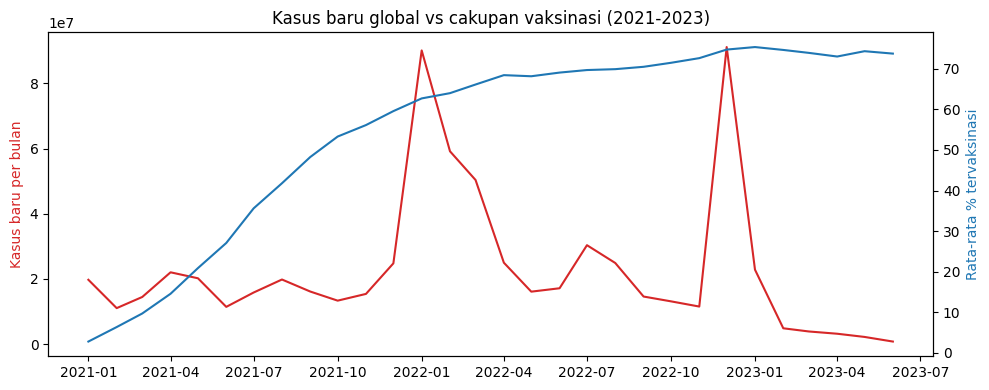

In [42]:
import matplotlib.pyplot as plt

# Visualisasi 1: kasus baru global per bulan vs rata-rata cakupan vaksinasi
m = (owid.withColumn("bulan", F.date_trunc("month", "date"))
         .groupBy("bulan")
         .agg(F.sum("new_cases").alias("kasus_baru"),
              F.avg("people_vaccinated_per_hundred").alias("vaksinasi"))
         .orderBy("bulan").toPandas())

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(m["bulan"], m["kasus_baru"], color="tab:red")
ax1.set_ylabel("Kasus baru per bulan", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(m["bulan"], m["vaksinasi"], color="tab:blue")
ax2.set_ylabel("Rata-rata % tervaksinasi", color="tab:blue")
plt.title("Kasus baru global vs cakupan vaksinasi (2021-2023)")
plt.tight_layout(); plt.show()

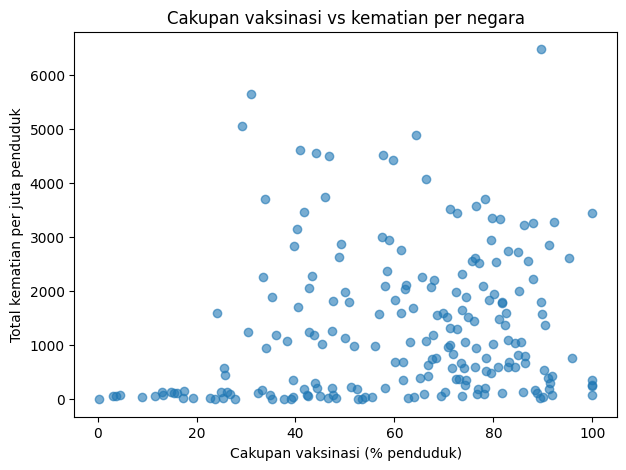

In [43]:
neg = (owid.groupBy("location", "continent")
       .agg(F.max("people_vaccinated_per_hundred").alias("vaks"),
            F.max("total_deaths_per_million").alias("kematian"))
       .toPandas().dropna())

plt.figure(figsize=(7, 5))
plt.scatter(neg["vaks"], neg["kematian"], alpha=0.6)
plt.xlabel("Cakupan vaksinasi (% penduduk)")
plt.ylabel("Total kematian per juta penduduk")
plt.title("Cakupan vaksinasi vs kematian per negara")
plt.show()

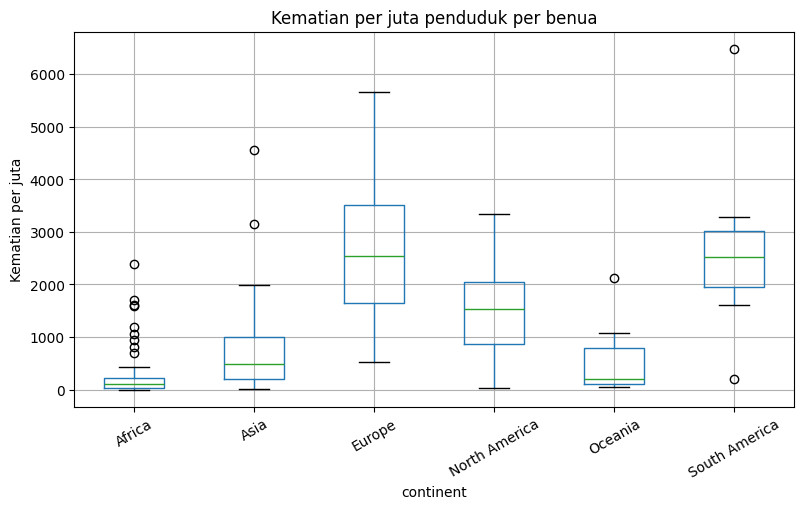

In [44]:
neg.boxplot(column="kematian", by="continent", figsize=(9, 5), rot=30)
plt.suptitle(""); plt.title("Kematian per juta penduduk per benua")
plt.ylabel("Kematian per juta"); plt.show()

In [45]:
n_owid = owid.select(F.col("location").alias("nama")).distinct()
n_who = who.select(F.col("Country").alias("nama")).distinct()
n_vax = vax.select(F.col("country").alias("nama")).distinct()

print("OWID tidak ada di WHO:", n_owid.join(n_who, "nama", "left_anti").count())
print("OWID tidak ada di VAX:", n_owid.join(n_vax, "nama", "left_anti").count())

print("\nDaftar OWID yang tidak ada di WHO:")
n_owid.join(n_who, "nama", "left_anti").show(60, truncate=False)

print("Daftar OWID yang tidak ada di VAX:")
n_owid.join(n_vax, "nama", "left_anti").show(60, truncate=False)

OWID tidak ada di WHO: 35
OWID tidak ada di VAX: 20

Daftar OWID yang tidak ada di WHO:
+-------------------------------+
|nama                           |
+-------------------------------+
|Macao                          |
|Kosovo                         |
|Bonaire Sint Eustatius and Saba|
|Curacao                        |
|Bolivia                        |
|Iran                           |
|Laos                           |
|Cape Verde                     |
|Hong Kong                      |
|Faeroe Islands                 |
|Cote d'Ivoire                  |
|Brunei                         |
|Falkland Islands               |
|Democratic Republic of Congo   |
|Russia                         |
|Turkey                         |
|Western Sahara                 |
|Taiwan                         |
|Reunion                        |
|Vatican                        |
|United States                  |
|Turkmenistan                   |
|Venezuela                      |
|Saint Barthelemy           